In [2]:
import os
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
else:
    print("Entrenando con CPU")
    
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print("Dispositivo:", device)

DATA_DIR = Path("../datasets/plant_village_image/Plant_leave_diseases_dataset_without_augmentation")
OUT_DIR = Path("outputs")
CKPT_DIR = Path("checkpoints")
OUT_DIR.mkdir(exist_ok=True)
CKPT_DIR.mkdir(exist_ok=True)

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Memoria: 6.0 GB
Dispositivo: cuda


In [3]:
IMG_SIZE = 128          # Usa 224 si comparas con ResNet18 / usas GPU con buena VRAM
BATCH_SIZE = 32
NUM_WORKERS =  0

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

full_train_ds = datasets.ImageFolder(root=DATA_DIR, transform=train_transform)
full_eval_ds = datasets.ImageFolder(root=DATA_DIR, transform=eval_transform)

class_names = full_train_ds.classes
num_classes = len(class_names)
targets = full_train_ds.targets
indices = np.arange(len(targets))

print(f"Total imágenes: {len(indices)} | Clases: {num_classes}")

# Split estratificado 70% train, 15% val, 15% test
train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, targets, test_size=0.30, stratify=targets, random_state=42
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

train_ds = Subset(full_train_ds, train_idx)
val_ds = Subset(full_eval_ds, val_idx)
test_ds = Subset(full_eval_ds, test_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

Total imágenes: 55448 | Clases: 39


In [4]:
class ConvBlock(nn.Module):
    def __init__(self, in_c: int, out_c: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

    def forward(self, x):
        return self.block(x)


class PlantCNN(nn.Module):
    def __init__(self, num_classes: int, img_size: int = 128):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),      # -> img_size/2
            ConvBlock(32, 64),     # -> img_size/4
            ConvBlock(64, 128),    # -> img_size/8
            ConvBlock(128, 256),   # -> img_size/16
        )
        feat_dim = img_size // 16
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256 * feat_dim * feat_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = PlantCNN(num_classes=num_classes, img_size=IMG_SIZE).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

Época 01/15 | Train Loss: 1.6755, Acc: 0.5252 | Val Loss: 0.8517, Acc: 0.7291
  -> Guardado mejor modelo en checkpoints\best_cnn_plantvillage.pt (val_acc=0.7291)
Época 02/15 | Train Loss: 0.9921, Acc: 0.6925 | Val Loss: 0.4723, Acc: 0.8554
  -> Guardado mejor modelo en checkpoints\best_cnn_plantvillage.pt (val_acc=0.8554)
Época 03/15 | Train Loss: 0.7648, Acc: 0.7606 | Val Loss: 0.4970, Acc: 0.8359
Época 04/15 | Train Loss: 0.6170, Acc: 0.8043 | Val Loss: 0.2719, Acc: 0.9139
  -> Guardado mejor modelo en checkpoints\best_cnn_plantvillage.pt (val_acc=0.9139)
Época 05/15 | Train Loss: 0.5253, Acc: 0.8322 | Val Loss: 0.2398, Acc: 0.9179
  -> Guardado mejor modelo en checkpoints\best_cnn_plantvillage.pt (val_acc=0.9179)
Época 06/15 | Train Loss: 0.4509, Acc: 0.8580 | Val Loss: 0.1647, Acc: 0.9505
  -> Guardado mejor modelo en checkpoints\best_cnn_plantvillage.pt (val_acc=0.9505)
Época 07/15 | Train Loss: 0.3960, Acc: 0.8734 | Val Loss: 0.1457, Acc: 0.9530
  -> Guardado mejor modelo en chec

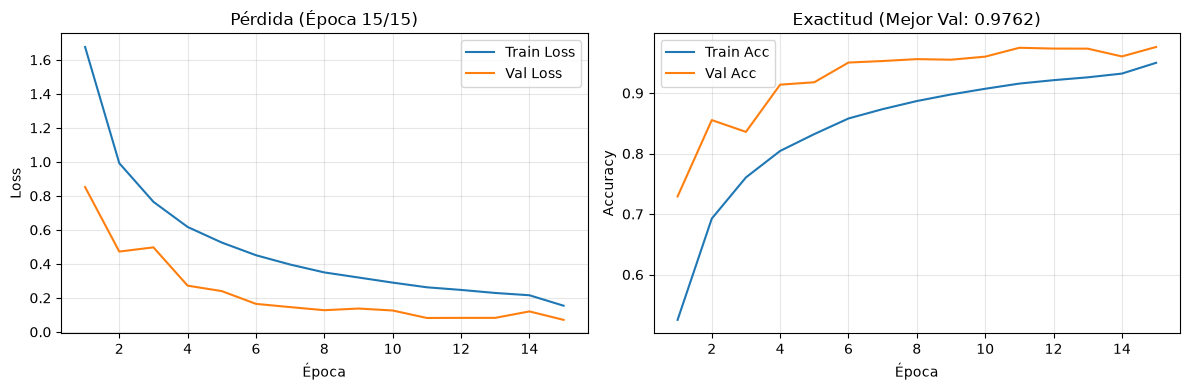

In [5]:
import time
from IPython.display import clear_output
import matplotlib.pyplot as plt


def run_epoch(model, loader, optimizer=None, log_every=50, epoch_num=None, total_epochs=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0
    num_batches = len(loader)
    phase = "Train" if is_train else "Val"
    start_t = time.time()

    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for batch_idx, (images, labels) in enumerate(loader, start=1):
            images, labels = images.to(device), labels.to(device)

            if is_train:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += batch_size

            if is_train and (batch_idx % log_every == 0 or batch_idx == num_batches):
                pct = 100.0 * batch_idx / num_batches
                running_loss = total_loss / total
                running_acc = correct / total
                elapsed = time.time() - start_t
                ep_str = f"Ep {epoch_num}/{total_epochs} | " if epoch_num else ""
                print(
                    f"  [{ep_str}{phase} {pct:5.1f}% ({batch_idx}/{num_batches})] "
                    f"Loss: {running_loss:.4f} | Acc: {running_acc:.4f} | {elapsed:.1f}s",
                    flush=True,
                )

    return total_loss / total, correct / total


EPOCHS = 15
best_val_acc = 0.0
best_model_path = CKPT_DIR / "best_cnn_plantvillage.pt"

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
epoch_logs = []

for epoch in range(1, EPOCHS + 1):
    print(f"\n--- Época {epoch:02d}/{EPOCHS:02d} ---", flush=True)
    tr_loss, tr_acc = run_epoch(
        model, train_loader, optimizer=optimizer, log_every=50, epoch_num=epoch, total_epochs=EPOCHS
    )
    va_loss, va_acc = run_epoch(
        model, val_loader, optimizer=None, log_every=50, epoch_num=epoch, total_epochs=EPOCHS
    )
    scheduler.step(va_acc)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    saved_msg = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "img_size": IMG_SIZE,
            "val_acc": best_val_acc,
        }, best_model_path)
        saved_msg = f"  -> Guardado mejor modelo en {best_model_path} (val_acc={best_val_acc:.4f})"

    epoch_logs.append(
        f"Época {epoch:02d}/{EPOCHS:02d} | "
        f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.4f} | "
        f"Val Loss: {va_loss:.4f}, Acc: {va_acc:.4f}"
        + (f"\n{saved_msg}" if saved_msg else "")
    )

    clear_output(wait=True)
    print("\n".join(epoch_logs), flush=True)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    epochs_x = range(1, len(history["train_loss"]) + 1)

    ax1.plot(epochs_x, history["train_loss"], label="Train Loss")
    ax1.plot(epochs_x, history["val_loss"], label="Val Loss")
    ax1.set_title(f"Pérdida (Época {epoch}/{EPOCHS})")
    ax1.set_xlabel("Época")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(epochs_x, history["train_acc"], label="Train Acc")
    ax2.plot(epochs_x, history["val_acc"], label="Val Acc")
    ax2.set_title(f"Exactitud (Mejor Val: {best_val_acc:.4f})")
    ax2.set_xlabel("Época")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

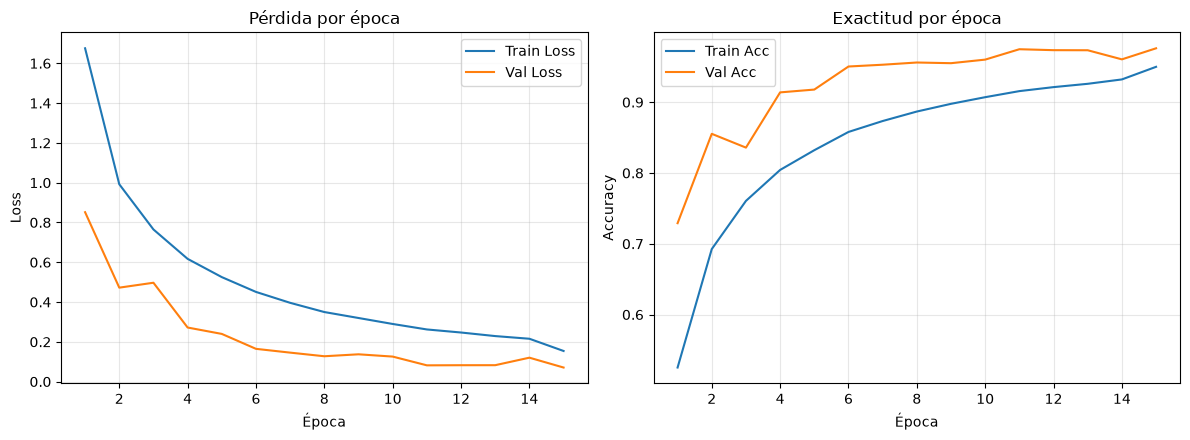


Test Accuracy: 0.9785
                                               precision    recall  f1-score   support

                           Apple___Apple_scab      0.948     0.979     0.963        94
                            Apple___Black_rot      0.989     0.989     0.989        93
                     Apple___Cedar_apple_rust      1.000     1.000     1.000        41
                              Apple___healthy      0.964     0.988     0.976       247
                    Background_without_leaves      0.988     0.982     0.985       171
                          Blueberry___healthy      0.987     0.987     0.987       226
                      Cherry___Powdery_mildew      0.994     0.987     0.990       158
                             Cherry___healthy      0.992     1.000     0.996       128
   Corn___Cercospora_leaf_spot Gray_leaf_spot      0.885     0.896     0.890        77
                           Corn___Common_rust      1.000     0.989     0.994       179
                  C

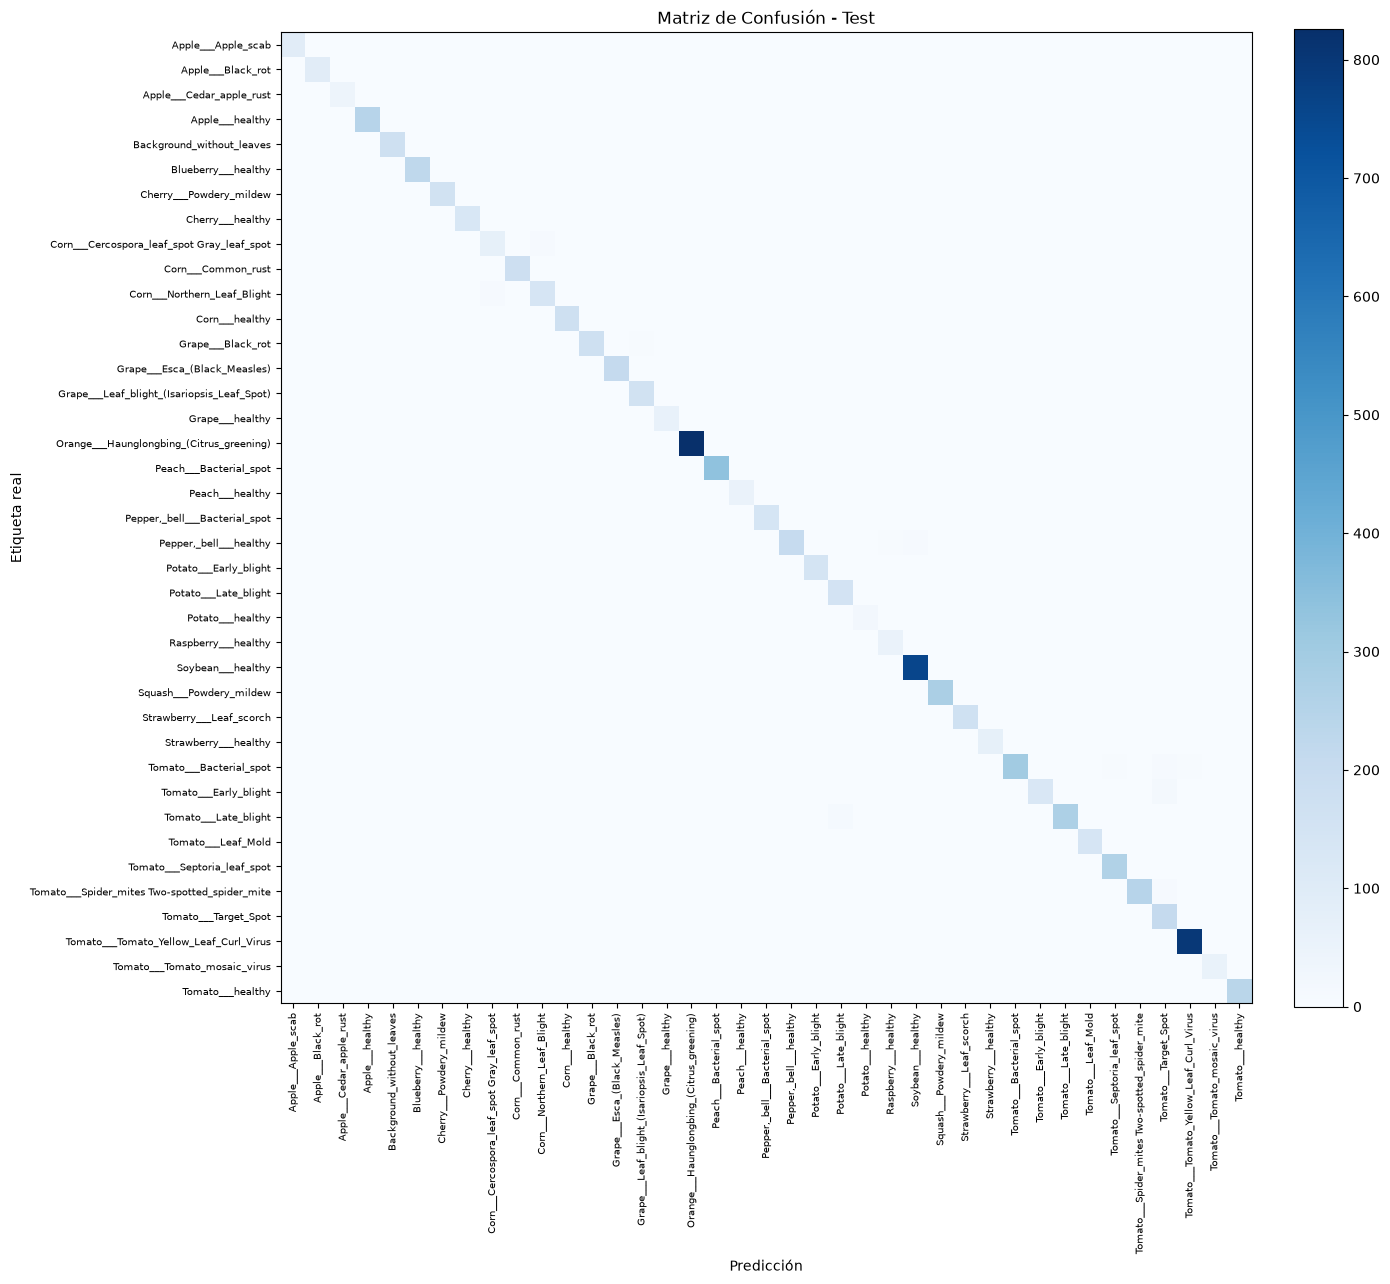

In [6]:
# 1. Pérdida y exactitud por época
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(epochs_range, history["train_loss"], label="Train Loss")
ax1.plot(epochs_range, history["val_loss"], label="Val Loss")
ax1.set_title("Pérdida por época")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, history["train_acc"], label="Train Acc")
ax2.plot(epochs_range, history["val_acc"], label="Val Acc")
ax2.set_title("Exactitud por época")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR / "curves_cnn.png", dpi=200)
plt.show()

# 2. Evaluación en TEST y matriz de confusión
ckpt = torch.load(best_model_path, map_location=device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

all_preds, all_labels, all_probs, all_imgs = [], [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = probs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())
        all_imgs.extend(images.cpu())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

print(f"\nTest Accuracy: {(all_preds == all_labels).mean():.4f}")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(14, 14))
im = ax.imshow(cm, cmap="Blues")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticklabels(class_names, fontsize=7)
ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta real")
ax.set_title("Matriz de Confusión - Test")
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=200)
plt.show()

Total mal clasificados en test: 179


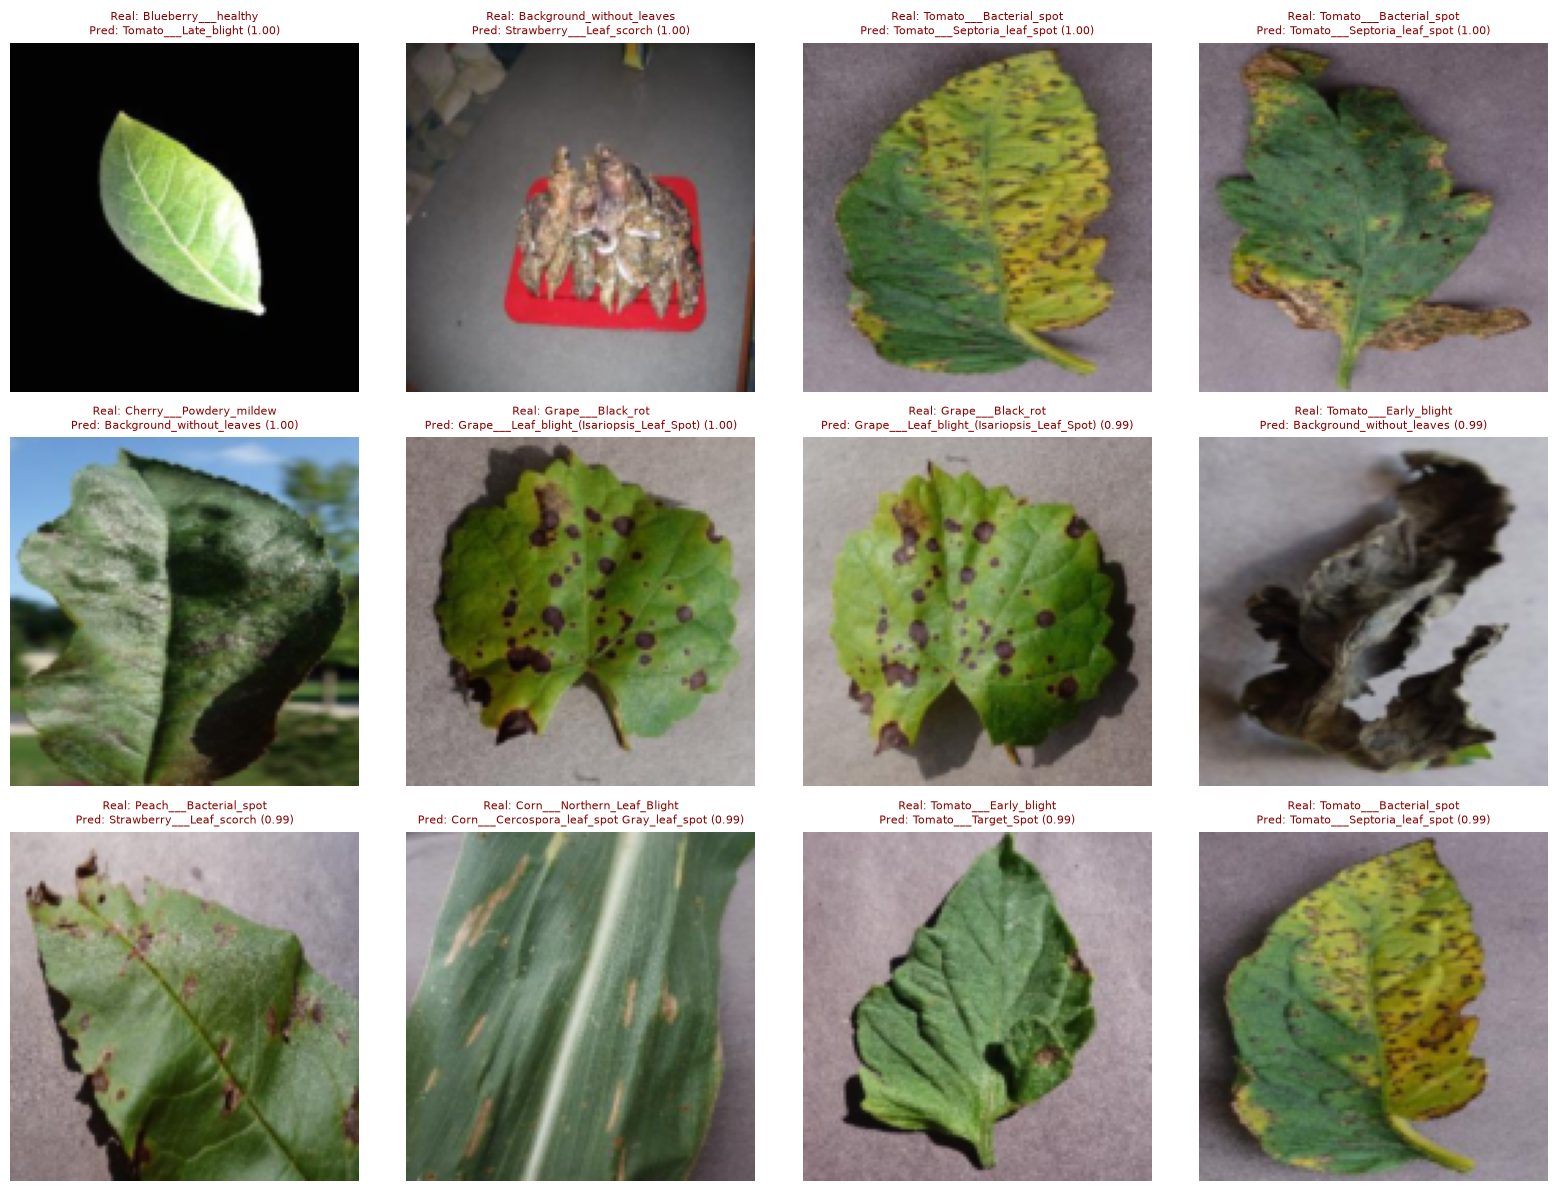

In [7]:
def denormalize(tensor_img):
    img = tensor_img.clone().numpy().transpose(1, 2, 0)
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0.0, 1.0)

wrong_idx = np.where(all_preds != all_labels)[0]
print(f"Total mal clasificados en test: {len(wrong_idx)}")

# Ordenar por mayor confianza errónea para detectar errores más llamativos
wrong_sorted = sorted(wrong_idx, key=lambda i: all_probs[i, all_preds[i]], reverse=True)
top_wrong = wrong_sorted[:12]

cols = 4
rows = int(np.ceil(len(top_wrong) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten()

for ax, idx in zip(axes, top_wrong):
    true_lbl = class_names[all_labels[idx]]
    pred_lbl = class_names[all_preds[idx]]
    conf = all_probs[idx, all_preds[idx]]
    ax.imshow(denormalize(all_imgs[idx]))
    ax.set_title(f"Real: {true_lbl}\nPred: {pred_lbl} ({conf:.2f})", fontsize=8, color="darkred")
    ax.axis("off")

for ax in axes[len(top_wrong):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUT_DIR / "misclassified_examples.png", dpi=200)
plt.show()

In [11]:
import torch

print("Versión de PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria GPU:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

    device = torch.device("cuda")

    x = torch.randn(5000, 5000, device=device)
    y = torch.randn(5000, 5000, device=device)

    z = torch.matmul(x, y)

    print("Operación completada:", z.shape)
else:
    print("No se detectó CUDA")

Versión de PyTorch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Memoria GPU: 6.0 GB
Operación completada: torch.Size([5000, 5000])


In [10]:
import torch
import torchvision
import numpy
import matplotlib
import sklearn

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No disponible")
print("Matplotlib:", matplotlib.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)

PyTorch: 2.11.0+cu128
CUDA: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Matplotlib: 3.11.2
NumPy: 2.4.6
Scikit-learn: 1.9.1
